<a href="https://colab.research.google.com/github/Digital-City-Lab-MUNI/Incremental-Learning-MycroftMinds/blob/main/notebooks/data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# prompt: connect to drive

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (15,8)

# Meteorological data

In [ ]:
meteo_file_path = '/content/drive/MyDrive/MyCroft Data/meteo_data_0.csv'

meteo_data = pd.read_csv(meteo_file_path)

print('\nShape:', meteo_data.shape,'\n')
meteo_data.head()


Shape: (564115, 59) 



,dateTime,usUnits,interval,barometer,pressure,altimeter,inTemp,outTemp,inHumidity,outHumidity,...,windBatteryStatus,rainBatteryStatus,outTempBatteryStatus,inTempBatteryStatus,cloudbase,windrun,cloudcover,aqi,visibility,humidex
0,1704063607,28.122289,11.448417,1069.693466,1002.549461,1068.574185,NaN,12.663842,NaN,102.416825,...,NaN,NaN,NaN,NaN,445.284266,10.443268,NaN,NaN,NaN,12.634540
1,1704063667,27.940057,11.443831,1073.046950,1005.058712,1040.885134,NaN,12.636567,NaN,105.161522,...,NaN,NaN,NaN,NaN,434.815965,10.445008,NaN,NaN,NaN,12.620366
2,1704063727,28.237231,11.430884,1128.777787,1032.193596,1068.674938,NaN,12.669738,NaN,102.461041,...,NaN,NaN,NaN,NaN,434.863894,10.442467,NaN,NaN,NaN,12.785041
3,1704063787,28.493802,11.435472,1091.024790,1043.835644,1040.939487,NaN,12.713868,NaN,104.504860,...,NaN,NaN,NaN,NaN,435.580647,10.442767,NaN,NaN,NaN,12.700933
4,1704063847,28.160142,11.447994,1056.312488,1060.539662,1051.091724,NaN,12.769091,NaN,103.323499,...,NaN,NaN,NaN,NaN,437.380130,10.442791,NaN,NaN,NaN,12.726492


In [ ]:
meteo_data.columns

Index(['dateTime', 'usUnits', 'interval', 'barometer', 'pressure', 'altimeter',
       'inTemp', 'outTemp', 'inHumidity', 'outHumidity', 'windSpeed',
       'windDir', 'windGust', 'windGustDir', 'rainRate', 'rain', 'dewpoint',
       'windchill', 'appTemp', 'heatindex', 'ET', 'radiation', 'UV',
       'extraTemp1', 'extraTemp2', 'extraTemp3', 'soilTemp1', 'soilTemp2',
       'soilTemp3', 'soilTemp4', 'leafTemp1', 'leafTemp2', 'extraHumid1',
       'extraHumid2', 'soilMoist1', 'soilMoist2', 'soilMoist3', 'soilMoist4',
       'leafWet1', 'leafWet2', 'rxCheckPercent', 'txBatteryStatus',
       'consBatteryVoltage', 'hail', 'hailRate', 'heatingTemp',
       'heatingVoltage', 'supplyVoltage', 'referenceVoltage',
       'windBatteryStatus', 'rainBatteryStatus', 'outTempBatteryStatus',
       'inTempBatteryStatus', 'cloudbase', 'windrun', 'cloudcover', 'aqi',
       'visibility', 'humidex'],
      dtype='object')

## Missing values

In [ ]:
meteo_data.isna().sum()

,0
dateTime,0
usUnits,0
interval,0
barometer,9
pressure,172374
altimeter,172374
inTemp,564115
outTemp,136522
inHumidity,564115
outHumidity,9


### Drop completely empty columns

In [ ]:
# find columns where all entries are nans
full_nan_columns = meteo_data.columns[meteo_data.isna().sum() == meteo_data.shape[0]]
# drop from table
meteo_data = meteo_data.drop(columns=full_nan_columns)
print(meteo_data.columns)
meteo_data.head()

Index(['dateTime', 'usUnits', 'interval', 'barometer', 'pressure', 'altimeter',
       'outTemp', 'outHumidity', 'windSpeed', 'windDir', 'windGust',
       'rainRate', 'rain', 'dewpoint', 'windchill', 'appTemp', 'heatindex',
       'ET', 'radiation', 'extraTemp1', 'cloudbase', 'windrun', 'humidex'],
      dtype='object')


,dateTime,usUnits,interval,barometer,pressure,altimeter,outTemp,outHumidity,windSpeed,windDir,...,dewpoint,windchill,appTemp,heatindex,ET,radiation,extraTemp1,cloudbase,windrun,humidex
0,1704063607,28.122289,11.448417,1069.693466,1002.549461,1068.574185,12.663842,102.416825,11.118473,288.969291,...,11.063217,12.682637,9.998148,12.708195,10.400040,10.4,12.585423,445.284266,10.443268,12.634540
1,1704063667,27.940057,11.443831,1073.046950,1005.058712,1040.885134,12.636567,105.161522,11.115148,278.100723,...,11.078087,12.572785,9.991198,12.662347,10.400041,10.4,12.594205,434.815965,10.445008,12.620366
2,1704063727,28.237231,11.430884,1128.777787,1032.193596,1068.674938,12.669738,102.461041,11.122942,286.036262,...,11.162717,12.684598,9.975972,12.754826,10.400039,10.4,12.560174,434.863894,10.442467,12.785041
3,1704063787,28.493802,11.435472,1091.024790,1043.835644,1040.939487,12.713868,104.504860,11.129976,288.390746,...,11.116352,12.734981,9.988581,12.740940,10.400040,10.4,12.561834,435.580647,10.442767,12.700933
4,1704063847,28.160142,11.447994,1056.312488,1060.539662,1051.091724,12.769091,103.323499,11.145599,286.208564,...,11.153900,12.685889,9.988616,12.815468,10.400041,10.4,12.519398,437.380130,10.442791,12.726492


/usr/local/lib/python3.11/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


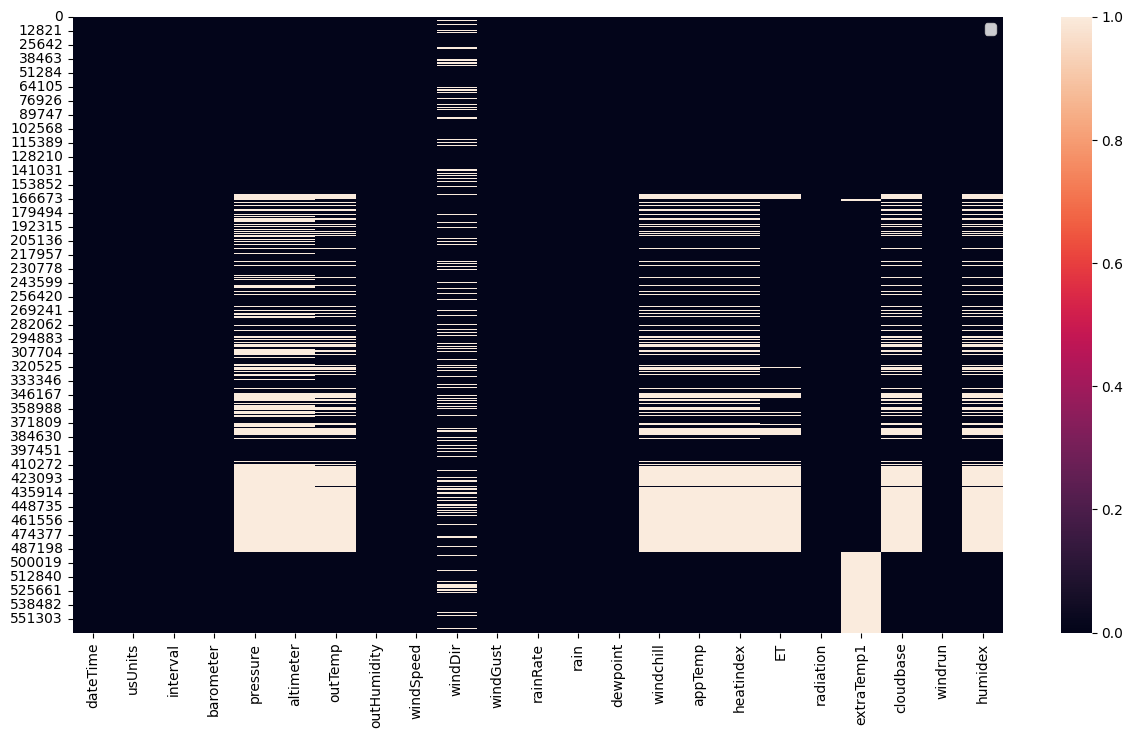

In [ ]:
sns.heatmap(meteo_data.isna())
plt.legend({1.0:'missing'})

In [ ]:
pd.concat(
    [meteo_data.count(), meteo_data.isna().sum(), ((meteo_data.isna().sum()/meteo_data.shape[0])*100).round(2)],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
dateTime,564115,0,0.00
usUnits,564115,0,0.00
interval,564115,0,0.00
barometer,564106,9,0.00
pressure,391741,172374,30.56
altimeter,391741,172374,30.56
outTemp,427593,136522,24.20
outHumidity,564106,9,0.00
windSpeed,564115,0,0.00
windDir,458500,105615,18.72


## Time

In [ ]:
meteo_data['time'] = pd.to_datetime(meteo_data["dateTime"], unit="s", utc=True)
meteo_data.head(7)

,dateTime,usUnits,interval,barometer,pressure,altimeter,outTemp,outHumidity,windSpeed,windDir,...,windchill,appTemp,heatindex,ET,radiation,extraTemp1,cloudbase,windrun,humidex,time
0,1704063607,28.122289,11.448417,1069.693466,1002.549461,1068.574185,12.663842,102.416825,11.118473,288.969291,...,12.682637,9.998148,12.708195,10.400040,10.4,12.585423,445.284266,10.443268,12.634540,2023-12-31 23:00:07+00:00
1,1704063667,27.940057,11.443831,1073.046950,1005.058712,1040.885134,12.636567,105.161522,11.115148,278.100723,...,12.572785,9.991198,12.662347,10.400041,10.4,12.594205,434.815965,10.445008,12.620366,2023-12-31 23:01:07+00:00
2,1704063727,28.237231,11.430884,1128.777787,1032.193596,1068.674938,12.669738,102.461041,11.122942,286.036262,...,12.684598,9.975972,12.754826,10.400039,10.4,12.560174,434.863894,10.442467,12.785041,2023-12-31 23:02:07+00:00
3,1704063787,28.493802,11.435472,1091.024790,1043.835644,1040.939487,12.713868,104.504860,11.129976,288.390746,...,12.734981,9.988581,12.740940,10.400040,10.4,12.561834,435.580647,10.442767,12.700933,2023-12-31 23:03:07+00:00
4,1704063847,28.160142,11.447994,1056.312488,1060.539662,1051.091724,12.769091,103.323499,11.145599,286.208564,...,12.685889,9.988616,12.815468,10.400041,10.4,12.519398,437.380130,10.442791,12.726492,2023-12-31 23:04:07+00:00
5,1704063907,28.002909,11.426826,1092.177181,1062.735102,1024.194222,12.730212,103.371117,11.140244,294.800193,...,12.789894,9.979058,12.789229,10.400038,10.4,12.579644,438.598288,10.443876,12.744336,2023-12-31 23:05:07+00:00
6,1704063967,27.965193,11.434872,1111.526058,1017.215645,1051.998496,12.855405,104.332876,11.113689,298.079972,...,12.779279,9.988623,12.688778,10.400039,10.4,12.571861,427.797648,10.443282,12.699158,2023-12-31 23:06:07+00:00


## Time frequency intervals

In [ ]:
print(meteo_data.set_index('time').resample('h').size().describe())
print('\nHead:')
display(meteo_data.set_index('time').resample('h').size().sort_values().head(15))
meteo_data.set_index('time').resample('h').size().sort_values().tail(15)

count    9403.000000
mean       59.993087
std         0.751978
min        16.000000
25%        60.000000
50%        60.000000
75%        60.000000
max       104.000000
dtype: float64

Head:


,0
time,
2024-10-27 00:00:00+00:00,16
2024-04-10 08:00:00+00:00,33
2025-01-26 17:00:00+00:00,35
2024-04-10 09:00:00+00:00,53
2024-08-10 07:00:00+00:00,54
2024-11-19 19:00:00+00:00,59
2024-06-03 08:00:00+00:00,59
2024-03-31 01:00:00+00:00,59
2024-09-17 20:00:00+00:00,60


,0
time,
2024-05-10 01:00:00+00:00,60
2024-05-10 02:00:00+00:00,60
2024-05-10 03:00:00+00:00,60
2024-05-10 12:00:00+00:00,60
2024-05-10 05:00:00+00:00,60
2024-05-10 06:00:00+00:00,60
2024-05-10 07:00:00+00:00,60
2024-05-10 08:00:00+00:00,60
2024-05-10 09:00:00+00:00,60


Check weird 104 values per minute

In [ ]:
meteo_data[(meteo_data['time'].dt.date == np.datetime64('2024-10-27')) & (meteo_data['time'].dt.hour==1)].head(50)

,dateTime,usUnits,interval,barometer,pressure,altimeter,outTemp,outHumidity,windSpeed,windDir,...,windchill,appTemp,heatindex,ET,radiation,extraTemp1,cloudbase,windrun,humidex,time
432036,1729990869,28.251757,11.462162,1081.513000,NaN,NaN,NaN,102.312135,10.400000,NaN,...,NaN,NaN,NaN,10.400056,10.4,21.557081,NaN,10.400000,NaN,2024-10-27 01:01:09+00:00
432037,1729990929,28.488686,11.488960,1053.331616,NaN,NaN,NaN,104.241387,10.400000,NaN,...,NaN,NaN,NaN,10.400056,10.4,22.011637,NaN,10.400000,NaN,2024-10-27 01:02:09+00:00
432038,1729990989,28.547511,11.456847,1116.559848,NaN,NaN,NaN,105.766514,10.400000,NaN,...,NaN,NaN,NaN,10.400057,10.4,21.991312,NaN,10.400000,NaN,2024-10-27 01:03:09+00:00
432039,1729991049,27.954351,11.440778,1031.867918,NaN,NaN,NaN,105.228780,10.400000,NaN,...,NaN,NaN,NaN,10.400055,10.4,22.087195,NaN,10.400000,NaN,2024-10-27 01:04:09+00:00
432040,1729991109,28.154686,11.432451,1107.817197,NaN,NaN,NaN,100.459010,11.013588,104.468547,...,NaN,NaN,NaN,10.400054,10.4,22.323051,NaN,10.436937,NaN,2024-10-27 01:05:09+00:00
432041,1729991168,28.170369,11.470467,1061.937448,NaN,NaN,NaN,103.411820,11.117753,105.014231,...,NaN,NaN,NaN,10.400055,10.4,22.039202,NaN,10.443398,NaN,2024-10-27 01:06:08+00:00
432042,1729991228,27.551834,11.466126,1091.116887,NaN,NaN,NaN,102.623139,11.124744,103.775822,...,NaN,NaN,NaN,10.400055,10.4,21.947873,NaN,10.443910,NaN,2024-10-27 01:07:08+00:00
432043,1729991288,27.661814,11.441252,1055.234828,NaN,NaN,NaN,106.199183,11.009928,104.544136,...,NaN,NaN,NaN,10.400059,10.4,21.724457,NaN,10.438392,NaN,2024-10-27 01:08:08+00:00
432044,1729991348,27.573597,11.454120,1068.667561,NaN,NaN,NaN,104.557286,11.016817,106.542233,...,NaN,NaN,NaN,10.400056,10.4,21.880057,NaN,10.437672,NaN,2024-10-27 01:09:08+00:00
432045,1729991408,28.136127,11.416791,1102.353341,NaN,NaN,NaN,104.308644,11.019745,103.571606,...,NaN,NaN,NaN,10.400054,10.4,22.258822,NaN,10.438210,NaN,2024-10-27 01:10:08+00:00


It looks like some values from `2024-10-27 00:00:00` might've moved to `2024-10-27 01:00:00`

## Time range of data

In [ ]:
print('We have data from:', meteo_data['time'].min(),'\nuntil:', meteo_data['time'].max())

We have data from: 2023-12-31 23:00:07+00:00 
until: 2025-01-26 17:34:02+00:00


In [ ]:
full_range = pd.DataFrame(
    index=pd.date_range(meteo_data['time'].min(),
                        meteo_data['time'].max(),
                        freq='min')
  )

print(full_range.index)
meteo_data_min = full_range.join(meteo_data, how='left').squeeze()
meteo_data_min

DatetimeIndex(['2023-12-31 23:00:07+00:00', '2023-12-31 23:01:07+00:00',
               '2023-12-31 23:02:07+00:00', '2023-12-31 23:03:07+00:00',
               '2023-12-31 23:04:07+00:00', '2023-12-31 23:05:07+00:00',
               '2023-12-31 23:06:07+00:00', '2023-12-31 23:07:07+00:00',
               '2023-12-31 23:08:07+00:00', '2023-12-31 23:09:07+00:00',
               ...
               '2025-01-26 17:24:07+00:00', '2025-01-26 17:25:07+00:00',
               '2025-01-26 17:26:07+00:00', '2025-01-26 17:27:07+00:00',
               '2025-01-26 17:28:07+00:00', '2025-01-26 17:29:07+00:00',
               '2025-01-26 17:30:07+00:00', '2025-01-26 17:31:07+00:00',
               '2025-01-26 17:32:07+00:00', '2025-01-26 17:33:07+00:00'],
              dtype='datetime64[ns, UTC]', length=564154, freq='min')


,dateTime,usUnits,interval,barometer,pressure,altimeter,outTemp,outHumidity,windSpeed,windDir,...,windchill,appTemp,heatindex,ET,radiation,extraTemp1,cloudbase,windrun,humidex,time
2023-12-31 23:00:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2023-12-31 23:01:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2023-12-31 23:02:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2023-12-31 23:03:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2023-12-31 23:04:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-01-26 17:29:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2025-01-26 17:30:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2025-01-26 17:31:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
2025-01-26 17:32:07+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT


# Smart meter data

In [ ]:
# read all smart_meter data files and concat them

import glob

all_files = glob.glob('/content/drive/MyDrive/MyCroft Data/smart_meter_data_*.csv')

li = []

for filename in all_files:
    df = pd.read_csv(filename, index_col=None, header=0)
    li.append(df)

smart_meter_data = pd.concat(li, axis=0, ignore_index=True)
# get rid of timezone
smart_meter_data['time'] = smart_meter_data['time'].apply(lambda x: x[:-6])
# turn to datetime
smart_meter_data['time'] = pd.to_datetime(smart_meter_data['time'], infer_datetime_format =True)
# sort by 'time'
smart_meter_data.sort_values(by=['time'], inplace=True)

print('\nShape:', smart_meter_data.shape, '\n')
smart_meter_data.head()

<ipython-input-14-5348b30a57b5>:17: UserWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  smart_meter_data['time'] = pd.to_datetime(smart_meter_data['time'], infer_datetime_format =True)



Shape: (4257624, 13) 



,time,device_id,serial_number,values_state,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,2024-01-01 00:00:01.818,e7803808-8743-4f1d-8c15-3d574a4bdf7c,73c48cf7-e53e-4548-802b-7971bf154f0c,NaN,101.053959,-635.689013,670.748839,912.812015,7788.926522,5179.064362,3565.426629,8656.644587,8767.779041
1,2024-01-01 00:00:03.671,a4b80cd7-5438-44cd-8257-c9ac81684822,d1e01b37-ad48-4df1-ad14-6e13d230b11a,NaN,580.350889,88.437225,590.806417,2087.377088,10.400000,582.029120,10.669146,2131.621335,589.340500
2,2024-01-01 00:00:05.524,2659da1f-9042-45c0-bf0a-625106aff7d1,9d57c045-ed26-4ee8-9039-302c16d8c478,NaN,88.760389,-1424.991659,1459.731053,8395.834012,5005.693161,5102.830154,7492.500722,13280.395948,12607.482568
3,2024-01-01 00:00:07.650,a806abdf-9261-4d98-abd4-a519248214f0,a39a6c1c-4992-4a91-be9b-ef9d4f411a51,NaN,10.472436,10.340116,10.496186,374.374368,10.400000,10.400000,246.197746,380.981669,10.400000
4,2024-01-01 00:00:08.667,fc529a25-d538-4c5b-b51e-2f27a3ce9f1a,0810a336-2fac-46e3-8029-57dda70375d7,NaN,10.593178,10.294157,10.629040,1111.791808,10.400000,10.400000,520.117300,1132.959947,10.400000


In [ ]:
smart_meter_data.describe()

,time,values_state,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
count,4257624,0.0,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257622e+06,4.257624e+06,4.257624e+06
mean,2024-06-30 20:43:00.341718528,NaN,7.039240e+01,-9.137543e+00,3.225422e+02,1.386879e+03,5.783489e+02,7.538119e+02,1.069650e+03,1.954853e+03,1.776910e+03
min,2024-01-01 00:00:01.818000,NaN,-2.301026e+04,-2.361441e+03,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01,1.040000e+01
25%,2024-03-31 04:55:13.284750080,NaN,1.045980e+01,-1.047457e+02,2.254765e+01,5.907761e+02,1.040000e+01,1.352155e+01,1.102317e+02,5.907848e+02,1.992162e+02
50%,2024-06-29 13:36:02.905500160,NaN,5.759210e+01,-2.834568e+00,1.376931e+02,1.052124e+03,1.040000e+01,6.605899e+01,3.185162e+02,1.056701e+03,6.116024e+02
75%,2024-10-02 07:00:25.451500032,NaN,1.162034e+02,1.040000e+01,2.799125e+02,1.672109e+03,1.040000e+01,3.681168e+02,9.121748e+02,1.756802e+03,1.161788e+03
max,2024-12-31 23:56:01.930000,NaN,1.127072e+04,1.420497e+04,2.601259e+04,9.919320e+03,2.737583e+04,2.975262e+04,1.573584e+04,3.702078e+04,4.540840e+04
std,NaN,NaN,7.289893e+02,7.374262e+02,1.017329e+03,1.536003e+03,2.896844e+03,2.930607e+03,2.151089e+03,4.064968e+03,4.810699e+03


## Missing data

In [ ]:
pd.concat(
    [smart_meter_data.count(), smart_meter_data.isna().sum(), (smart_meter_data.isna().sum()/smart_meter_data.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
time,4257624,0,0.000000
device_id,4257624,0,0.000000
serial_number,4257624,0,0.000000
values_state,0,4257624,100.000000
total_power_active,4257622,2,0.000047
total_power_reactive,4257622,2,0.000047
total_power_apparent,4257622,2,0.000047
import_energy_active,4257622,2,0.000047
export_energy_active,4257622,2,0.000047
import_energy_reactive,4257622,2,0.000047


In [ ]:
smart_meter_data = smart_meter_data.drop(columns=['values_state'])

## Unique devices and serial numbers

In [ ]:
print("Number of unique device ids:", len(smart_meter_data.device_id.unique()))
print("Number of unique serial numbers:", len(smart_meter_data.serial_number.unique()))

Number of unique device ids: 41
Number of unique serial numbers: 41


## Check whether each unique device_id have only one unique serial_number in smart_meter_data


In [ ]:
smart_meter_data.groupby('device_id')['serial_number'].nunique().max()

1

Yes, so we can use device_id as primary key in our operations

## Time range of data

In [ ]:
print('We have data from:', smart_meter_data['time'].min(),
      '\nuntil:', smart_meter_data['time'].max())


We have data from: 2024-01-01 00:00:01.818000 
until: 2024-12-31 23:56:01.930000


## Time frequency intervals

In [ ]:
smart_meter_data.groupby('device_id')['time'].diff().describe()

,time
count,4257583
mean,0 days 00:05:04.516912982
std,0 days 00:17:53.101294801
min,0 days 00:00:00
25%,0 days 00:04:59.965000
50%,0 days 00:05:00.077000
75%,0 days 00:05:00.201000
max,3 days 22:58:26.201000


Average interval is **5 mins**, also it appears that some meters might have latent (skipped timeseries that can't be detected by `isna()`) missing data

Thoughts..

1. We'd probably need to look at data for individual meters, so 41 different time series.
- Individual meter data readings seem to have a granulairty of 5mins
2. Meteorological data is recorded per minute.
- Need to think what is the best way to merge meteo data to meter readings.

## Do all meters have the same amount of data?

In [ ]:
print(smart_meter_data.groupby('device_id')['time'].count().sort_values())
smart_meter_data.groupby('device_id')['time'].count().describe()

device_id
a2aee527-f5e2-41c1-9da0-6c4fd1b1d4ba    103515
114b44b0-0dc4-45d6-a4ac-83223ea9b2d8    103738
a806abdf-9261-4d98-abd4-a519248214f0    103772
615c3df8-9ef6-4aa1-994a-87c2a7ffa0cc    103785
b14559e0-1c2e-417e-a736-f92a39bec0db    103850
8e0a1d6f-8ba6-4d0c-a025-378ace0f7291    103857
12db0eaf-e9e5-4cb5-849c-3289ef475f02    103857
84faf80e-e9d5-4552-b919-fbb8df7c7e4a    103858
4ad3e3e6-5f11-4923-a88d-668b4ddb493a    103859
4a448440-d2dd-4b27-ae02-87e7e3baa9f5    103859
61be69b4-a02a-48f8-8431-d4f07aad36d2    103859
1540b469-3e7e-4e8e-89fb-a1aceaf8dbd6    103859
265064b5-79b8-4436-8bc7-3f24062d73c3    103859
478e1210-ead4-4d55-9d35-c1090fbeb354    103859
3f3f551c-6594-4098-b9b4-af9ac4ab606c    103859
021ebc46-e284-461a-92bb-6236c7768774    103859
a5a90155-e8a3-473e-a709-3a1ae21c9a93    103859
69a3bfa0-e8e6-41be-8c42-65e899a37794    103859
62c4699f-2e30-494b-a945-0801ccaf7bf9    103859
8f361e91-54a8-4f05-bab5-a672fc9d82b6    103859
8f3a5182-51f7-4a43-a580-f272cd1c4481    103859
51c

,time
count,41.000000
mean,103844.487805
std,58.665203
min,103515.000000
25%,103859.000000
50%,103859.000000
75%,103862.000000
max,103864.000000


No, most meters have 103_859 entries, but the others vary

## Min-Max range of each meter

In [ ]:
smart_meter_data.groupby('device_id')['time'].agg(['min', 'max']).sort_values('min')

,min,max
device_id,,
e7803808-8743-4f1d-8c15-3d574a4bdf7c,2024-01-01 00:00:01.818,2024-12-31 23:55:47.715
a4b80cd7-5438-44cd-8257-c9ac81684822,2024-01-01 00:00:03.671,2024-12-31 23:55:49.355
2659da1f-9042-45c0-bf0a-625106aff7d1,2024-01-01 00:00:05.524,2024-12-31 23:55:51.017
a806abdf-9261-4d98-abd4-a519248214f0,2024-01-01 00:00:07.650,2024-12-31 23:55:53.778
fc529a25-d538-4c5b-b51e-2f27a3ce9f1a,2024-01-01 00:00:08.667,2024-12-31 23:55:54.858
3617dc75-38d4-4875-b66c-64f896b5c9f1,2024-01-01 00:00:11.628,2024-12-31 23:55:52.684
c72b9342-827b-484c-a16a-1b4019f47720,2024-01-01 00:00:13.653,2024-12-31 23:55:55.863
231e45ef-ca7a-4f80-be11-ac7e2da0274c,2024-01-01 00:00:14.671,2024-12-31 23:55:56.903
947ed086-5ce2-436f-bf18-aaabac14e71d,2024-01-01 00:00:15.588,2024-12-31 23:55:57.908


Almost each meter:
- starts at `2024-01-01 00:00:00`;
- ends at `2024-12-31 23:55:46`.

## Single smart_meter

In [ ]:
smart_meter_data[smart_meter_data.device_id == 'e7803808-8743-4f1d-8c15-3d574a4bdf7c'].head()

,time,device_id,serial_number,total_power_active,total_power_reactive,total_power_apparent,import_energy_active,export_energy_active,import_energy_reactive,export_energy_reactive,total_energy_active,total_energy_reactive
0,2024-01-01 00:00:01.818,e7803808-8743-4f1d-8c15-3d574a4bdf7c,73c48cf7-e53e-4548-802b-7971bf154f0c,101.053959,-635.689013,670.748839,912.812015,7788.926522,5179.064362,3565.426629,8656.644587,8767.779041
41,2024-01-01 00:05:01.977,e7803808-8743-4f1d-8c15-3d574a4bdf7c,73c48cf7-e53e-4548-802b-7971bf154f0c,96.819494,-644.394833,682.549954,936.485998,7644.014737,5151.619166,3409.884853,8974.242870,8572.349470
82,2024-01-01 00:10:02.060,e7803808-8743-4f1d-8c15-3d574a4bdf7c,73c48cf7-e53e-4548-802b-7971bf154f0c,98.979833,-602.612927,646.299022,927.503828,7510.117676,5115.758429,3571.343915,8618.084388,8565.607582
123,2024-01-01 00:15:02.239,e7803808-8743-4f1d-8c15-3d574a4bdf7c,73c48cf7-e53e-4548-802b-7971bf154f0c,96.121584,-632.938492,700.471923,921.692728,7484.206677,5080.445433,3449.793571,8580.803242,8236.807656
164,2024-01-01 00:20:01.496,e7803808-8743-4f1d-8c15-3d574a4bdf7c,73c48cf7-e53e-4548-802b-7971bf154f0c,97.115153,-619.859449,688.859114,956.451870,7734.972119,5072.945249,3401.639661,8396.998525,8555.173121


### Range of individual meter

In [ ]:
meter_data_1 = smart_meter_data[smart_meter_data.device_id == 'e7803808-8743-4f1d-8c15-3d574a4bdf7c'].sort_values('time').reset_index()
meter_data_1 = meter_data_1.drop(columns=['device_id', 'serial_number'])
print('Min:', meter_data_1['time'].min(),'\nMax:', meter_data_1['time'].max())

Min: 2024-01-01 00:00:01.818000 
Max: 2024-12-31 23:55:47.715000


### Time frequency of data

In [ ]:
print("Describe:")
display(meter_data_1.set_index('time').resample('h').size().describe())

print('\nHead:')
display(meter_data_1.set_index('time').resample('h').size().sort_values().head(45))

print('\nTail:')
meter_data_1.set_index('time').resample('h').size().sort_values().tail(5)

Describe:


,0
count,8784.000000
mean,11.823998
std,1.424877
min,0.000000
25%,12.000000
50%,12.000000
75%,12.000000
max,24.000000



Head:


,0
time,
2024-12-06 00:00:00,0
2024-11-20 00:00:00,0
2024-11-20 01:00:00,0
2024-11-20 02:00:00,0
2024-11-20 04:00:00,0
2024-11-20 03:00:00,0
2024-11-20 05:00:00,0
2024-11-20 06:00:00,0
2024-11-19 23:00:00,0



Tail:


,0
time,
2024-05-05 15:00:00,12
2024-05-05 16:00:00,12
2024-05-07 01:00:00,12
2024-05-07 03:00:00,12
2024-10-27 02:00:00,24


### Time differences for the meter

In [ ]:
meter_time_diff = meter_data_1['time'].diff().dropna().sort_values()  # drop NAT for the 1st value

print("Describe:")
display(meter_time_diff.describe())

print('\nHead:')
display(meter_time_diff.head(15))

print('\nTail:')
meter_time_diff.tail(42)

Describe:


,time
count,103861
mean,0 days 00:05:04.466025717
std,0 days 00:17:51.679352185
min,0 days 00:00:00.022000
25%,0 days 00:04:59.966000
50%,0 days 00:05:00.074000
75%,0 days 00:05:00.194000
max,3 days 22:58:08.816000



Head:


,time
85031,0 days 00:00:00.022000
85029,0 days 00:00:00.043000
85033,0 days 00:00:00.103000
85043,0 days 00:00:00.242000
85041,0 days 00:00:00.305000
85037,0 days 00:00:00.375000
85047,0 days 00:00:00.463000
85049,0 days 00:00:00.797000
85045,0 days 00:00:08.595000
85035,0 days 00:00:08.648000



Tail:


,time
81705,0 days 00:05:13.958000
80684,0 days 00:05:22.460000
76838,0 days 00:05:22.522000
74022,0 days 00:06:51.476000
74024,0 days 00:09:05.052000
37787,0 days 00:09:59.168000
12458,0 days 00:09:59.449000
71131,0 days 00:09:59.569000
63769,0 days 00:09:59.647000
24663,0 days 00:09:59.835000


#### Look at periods where the differences are less than 5 minutes (includes two entries to see the difference in data)
Read the table from the beginning and consider entries in pairs:
- 76838 - 78839 (first pair)
- 78508 - 78509 (second pair)
- ...
- 85048 - 85049 (last pair)


In [ ]:
less_5_min_plus_next = meter_time_diff.head(15).index.append(
    meter_time_diff.head(15).index-1
    )

meter_data_1.loc[less_5_min_plus_next][['time','total_power_active']].sort_values('time').join(
    meter_time_diff.head(15), rsuffix='_difference')

,time,total_power_active,time_difference
76838,2024-09-28 14:56:10.820,166.444063,NaT
76839,2024-09-28 15:00:47.827,100.588470,0 days 00:04:37.007000
78508,2024-10-04 10:06:01.626,119.896298,NaT
78509,2024-10-04 10:10:47.622,133.740621,0 days 00:04:45.996000
82028,2024-10-16 16:11:01.712,136.274082,NaT
82029,2024-10-16 16:15:47.762,222.275026,0 days 00:04:46.050000
85026,2024-10-27 02:00:48.052,96.418765,NaT
85027,2024-10-27 02:00:56.954,95.200419,0 days 00:00:08.902000
85028,2024-10-27 02:05:48.063,99.443570,NaT
85029,2024-10-27 02:05:48.106,98.658112,0 days 00:00:00.043000


Here we can see that the `2024-10-27 02:00:00` hours is doubled for some reason, but some inconsistencies also happen in other time periods

#### Look at periods where the differences are bigger than 5 minutes (includes two entries to see the difference in data)
Read the table from the beginning and consider entries in pairs:

In [ ]:
more_5_min_plus_next = meter_time_diff.tail(25).index.append(
    meter_time_diff.tail(25).index-1
    )

meter_data_1.loc[more_5_min_plus_next][['time','total_power_active']].sort_values('time').join(
    meter_time_diff.tail(25), rsuffix='_difference')

,time,total_power_active,time_difference
25938,2024-03-31 01:55:02.301,98.369418,NaT
25939,2024-03-31 03:00:01.658,98.213473,0 days 01:04:59.357000
40100,2024-05-19 07:15:02.294,99.072045,NaT
40101,2024-05-19 08:20:02.212,96.033665,0 days 01:04:59.918000
40131,2024-05-19 10:50:01.665,114.776233,NaT
40132,2024-05-19 11:45:01.818,99.508143,0 days 00:55:00.153000
43446,2024-05-30 23:55:02.349,99.450230,NaT
43447,2024-05-31 02:45:02.468,96.962684,0 days 02:50:00.119000
61953,2024-08-03 08:55:01.574,98.308816,NaT
61954,2024-08-03 09:25:02.205,96.235030,0 days 00:30:00.631000


Most of the inconsistencies are happening in September, but the others are randomly spread throughout the time

### Grouped data for one meter

#### Original (5 min)

##### `total_energy_active`

<Axes: xlabel='time', ylabel='total_energy_active'>

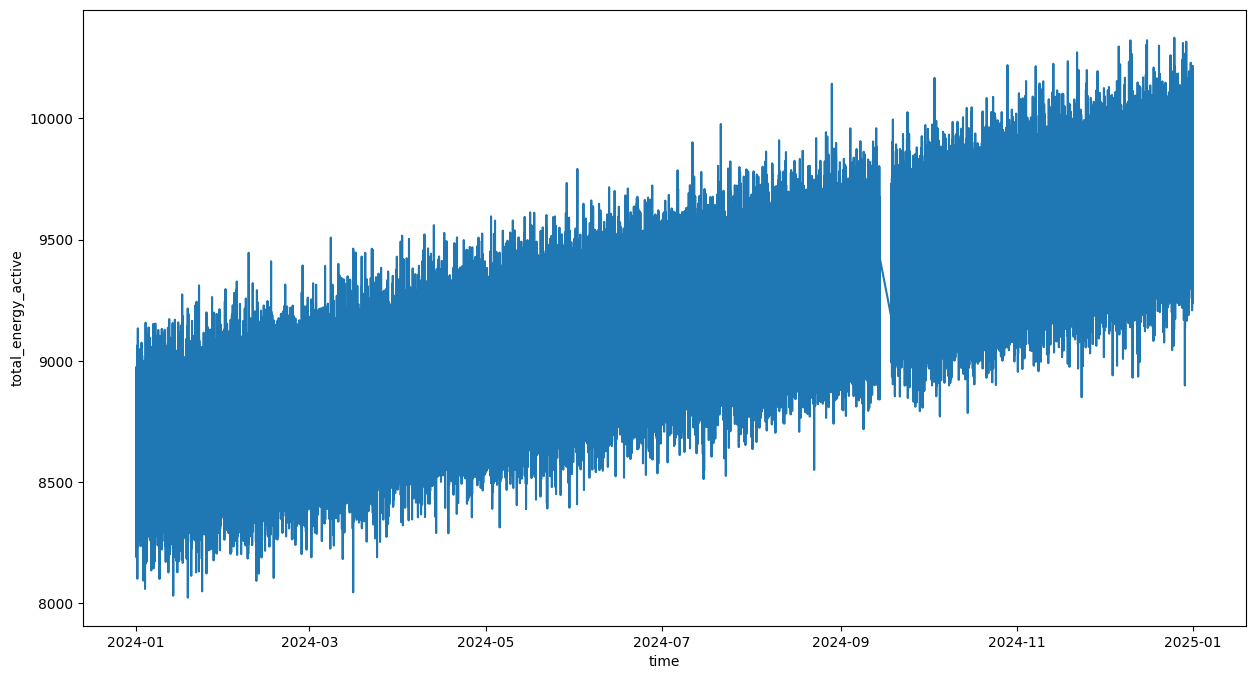

In [ ]:
plt.figure(figsize=(15,8))
sns.lineplot(x=meter_data_1['time'], y=meter_data_1['total_energy_active'])

###### Missing data in September

<Axes: xlabel='time', ylabel='total_energy_active'>

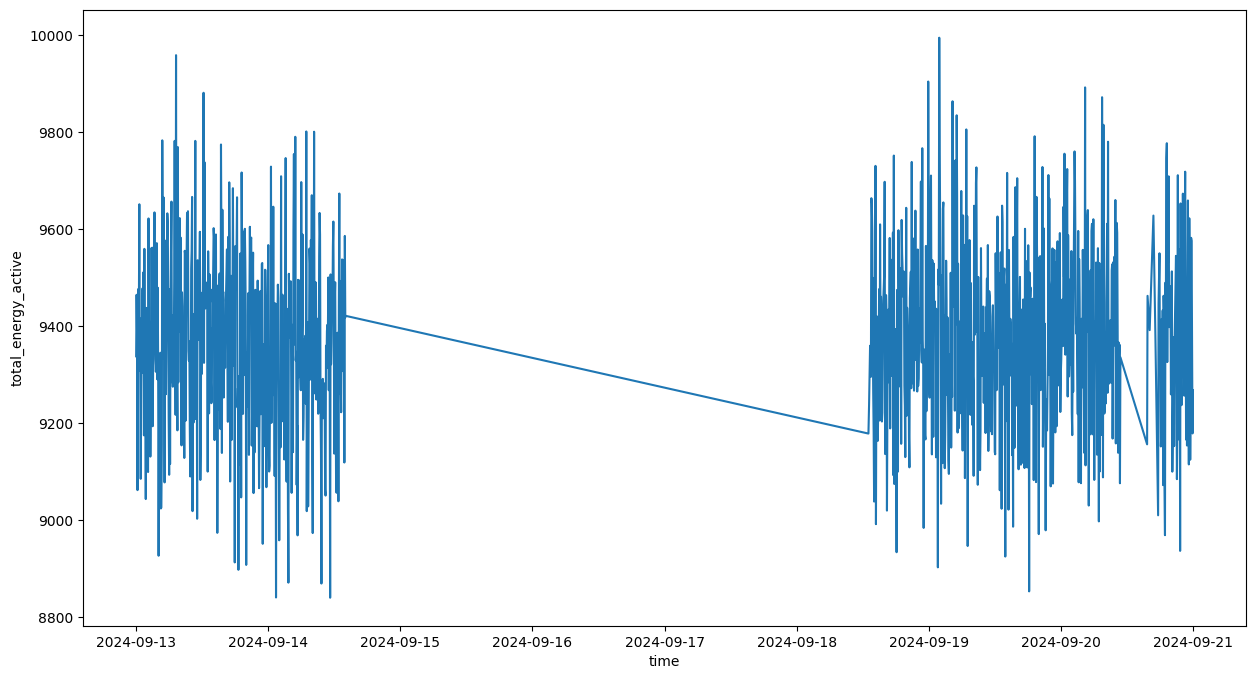

In [ ]:
date_range = pd.date_range('2024-09-13', '2024-09-21', freq='min')
sns.lineplot(
    x=meter_data_1['time'][meter_data_1['time'].dt.floor('min').isin(date_range)],
    y=meter_data_1[meter_data_1['time'].dt.floor('min').isin(date_range)]['total_energy_active']
    )

##### `total_power_active`


<Axes: xlabel='time', ylabel='total_power_active'>

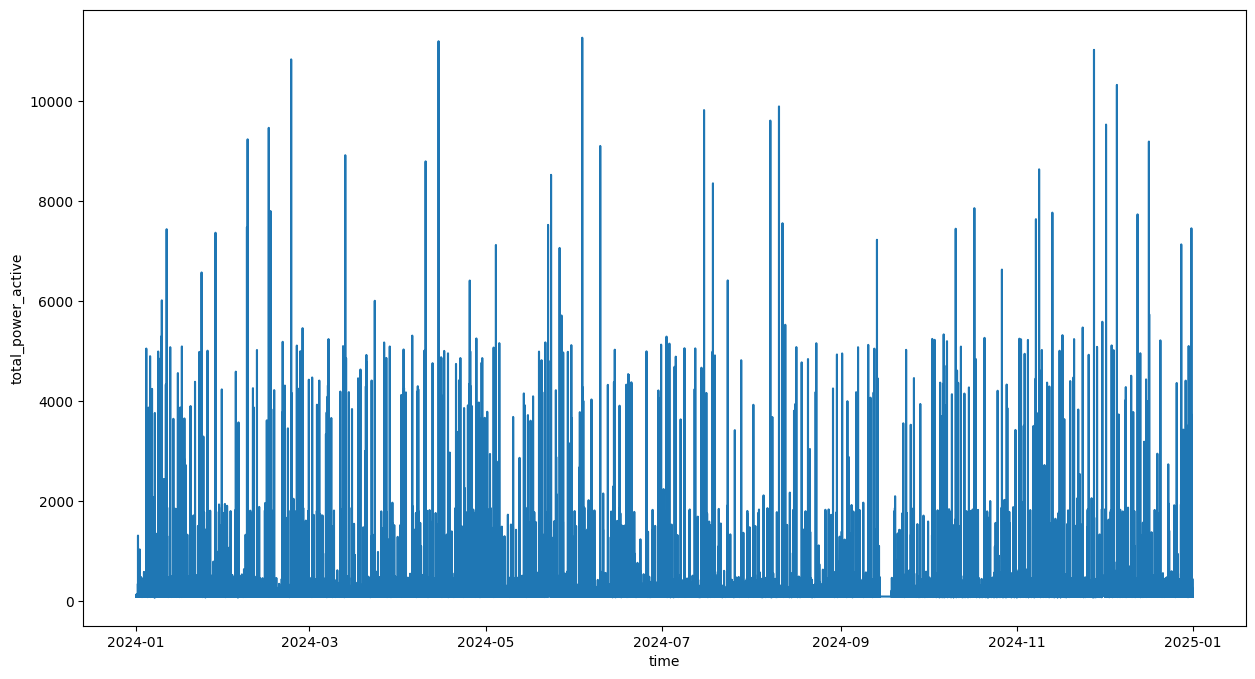

In [ ]:
sns.lineplot(x=meter_data_1['time'], y=meter_data_1['total_power_active'])

<Axes: xlabel='time', ylabel='total_power_active'>

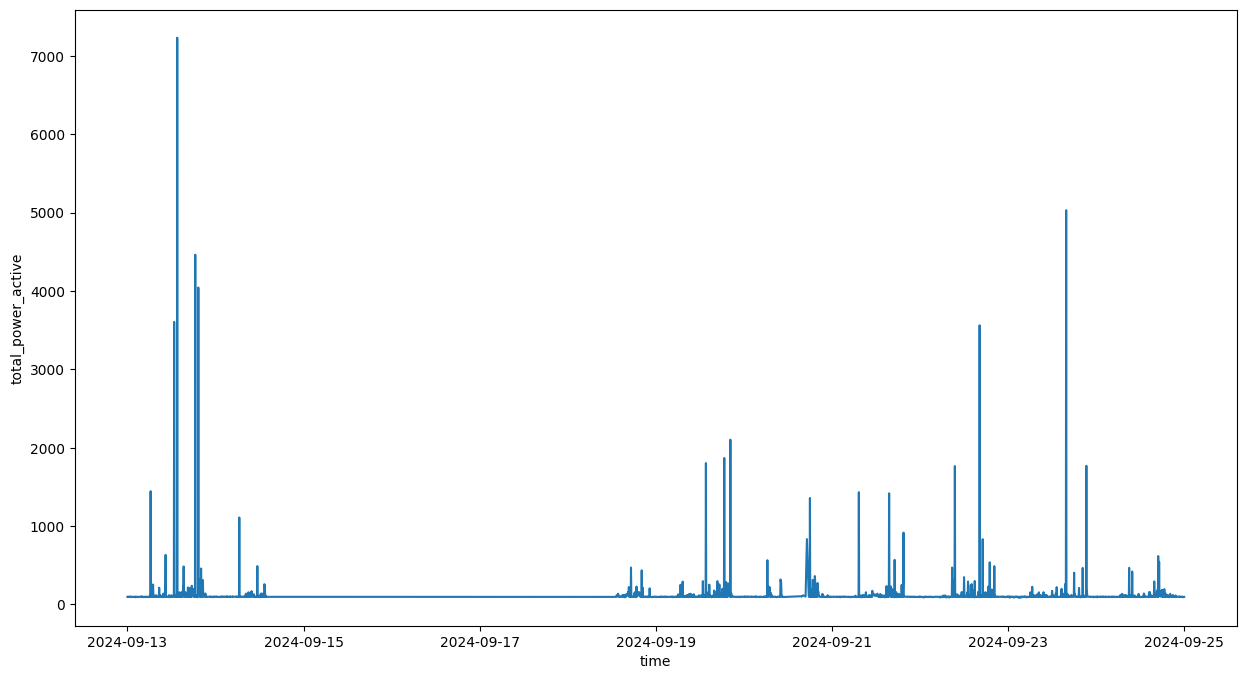

In [ ]:
date_range = pd.date_range('2024-09-13', '2024-09-25', freq='min')
sns.lineplot(
    x=meter_data_1['time'][meter_data_1['time'].dt.floor('min').isin(date_range)],
    y=meter_data_1[meter_data_1['time'].dt.floor('min').isin(date_range)]['total_power_active']
    )

#### Hourly

##### `total_energy_active`

DatetimeIndex(['2024-01-01 00:00:00', '2024-01-01 01:00:00',
               '2024-01-01 02:00:00', '2024-01-01 03:00:00',
               '2024-01-01 04:00:00', '2024-01-01 05:00:00',
               '2024-01-01 06:00:00', '2024-01-01 07:00:00',
               '2024-01-01 08:00:00', '2024-01-01 09:00:00',
               ...
               '2024-12-31 14:00:00', '2024-12-31 15:00:00',
               '2024-12-31 16:00:00', '2024-12-31 17:00:00',
               '2024-12-31 18:00:00', '2024-12-31 19:00:00',
               '2024-12-31 20:00:00', '2024-12-31 21:00:00',
               '2024-12-31 22:00:00', '2024-12-31 23:00:00'],
              dtype='datetime64[ns]', length=8784, freq='h')


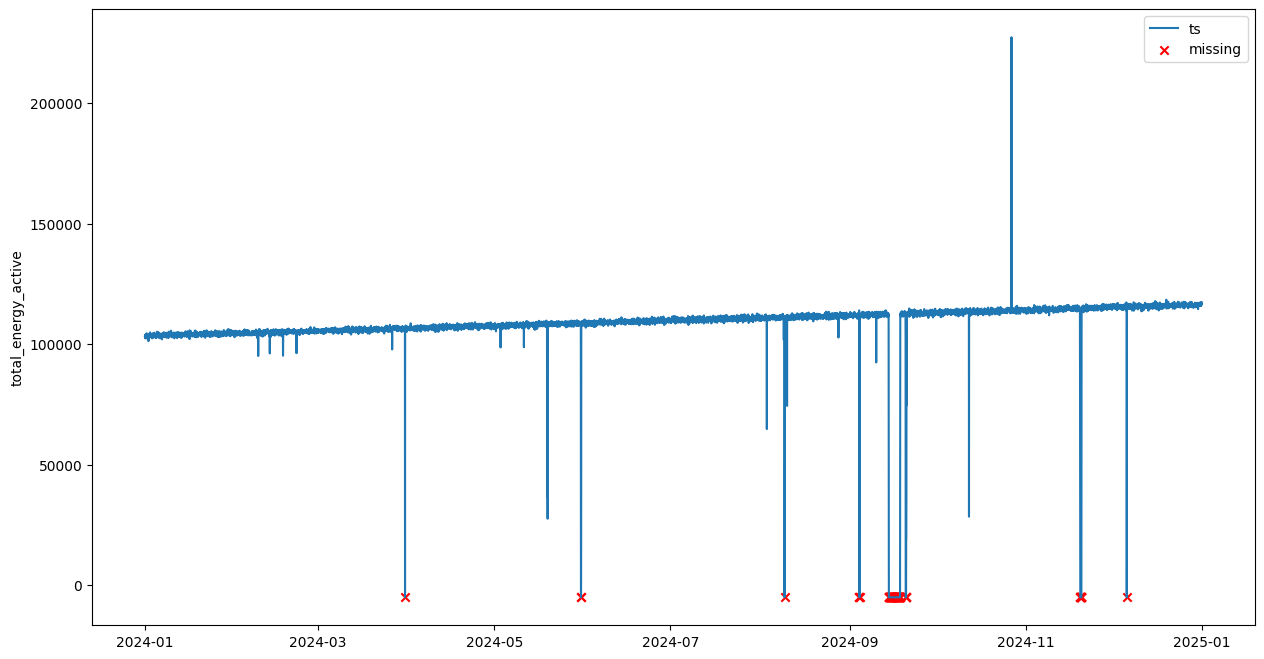

In [ ]:
plt.figure(figsize=(15,8))
hourly_meter_data = meter_data_1.groupby(meter_data_1['time'].dt.floor('h'))
full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_data.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_data.indices.keys()).max(), freq='h')
    )
print(full_range.index)
tot_eng_hour_endog = full_range.join(hourly_meter_data['total_energy_active'].sum(), how='left').squeeze()

sns.lineplot(tot_eng_hour_endog.fillna(-5000), label='ts')
plt.scatter(
    x=tot_eng_hour_endog[tot_eng_hour_endog.isna()].index,
    y=[-5000]*tot_eng_hour_endog[tot_eng_hour_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

##### `total_power_active`


DatetimeIndex(['2024-01-01 00:00:00', '2024-01-01 01:00:00',
               '2024-01-01 02:00:00', '2024-01-01 03:00:00',
               '2024-01-01 04:00:00', '2024-01-01 05:00:00',
               '2024-01-01 06:00:00', '2024-01-01 07:00:00',
               '2024-01-01 08:00:00', '2024-01-01 09:00:00',
               ...
               '2024-12-31 14:00:00', '2024-12-31 15:00:00',
               '2024-12-31 16:00:00', '2024-12-31 17:00:00',
               '2024-12-31 18:00:00', '2024-12-31 19:00:00',
               '2024-12-31 20:00:00', '2024-12-31 21:00:00',
               '2024-12-31 22:00:00', '2024-12-31 23:00:00'],
              dtype='datetime64[ns]', length=8784, freq='h')


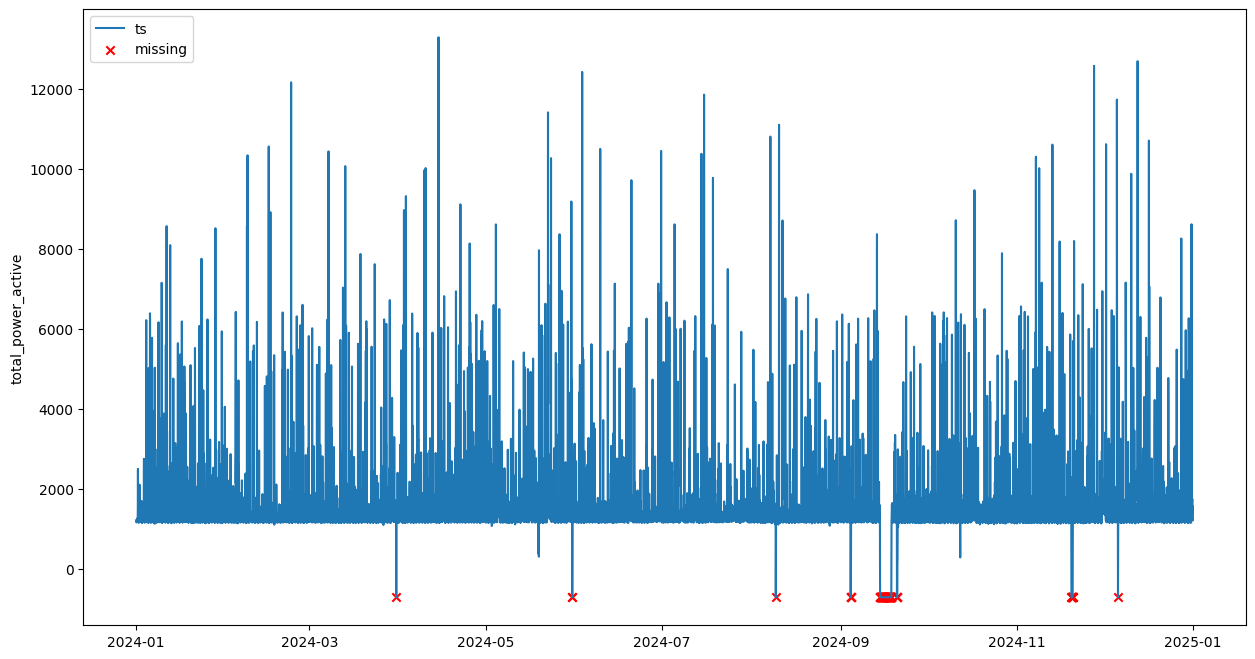

In [ ]:
plt.figure(figsize=(15,8))
hourly_meter_data = meter_data_1.groupby(meter_data_1['time'].dt.floor('h'))
full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_data.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_data.indices.keys()).max(), freq='h')
    )
print(full_range.index)
tot_pow_hour_endog = full_range.join(hourly_meter_data['total_power_active'].sum(), how='left').squeeze()

sns.lineplot(tot_pow_hour_endog.fillna(-700), label='ts')
plt.scatter(
    x=tot_pow_hour_endog[tot_pow_hour_endog.isna()].index,
    y=[-700]*tot_pow_hour_endog[tot_pow_hour_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

#### Daily

##### `total_energy_active`

DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05', '2024-01-06', '2024-01-07', '2024-01-08',
               '2024-01-09', '2024-01-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[ns]', length=366, freq='D')


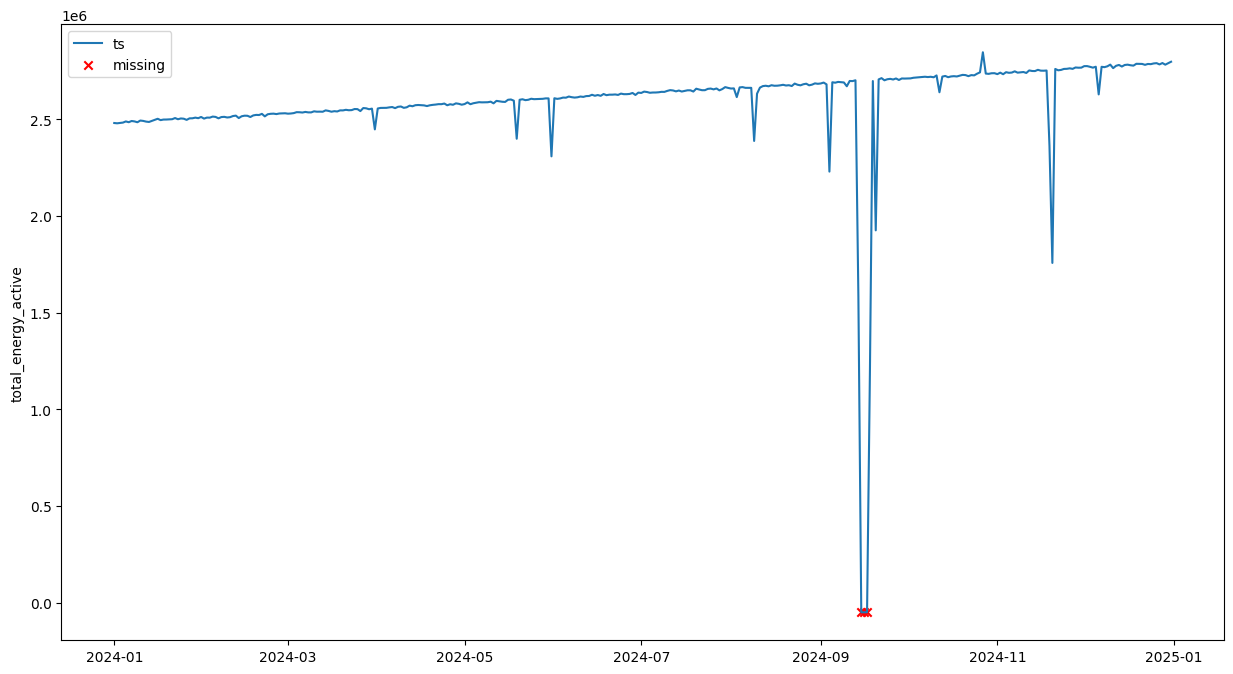

In [ ]:
plt.figure(figsize=(15,8))
daily_meter_data = meter_data_1.groupby(meter_data_1['time'].dt.floor('d'))

full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_data.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_data.indices.keys()).max(), freq='d')
    )
print(full_range.index)

tot_eng_day_endog = full_range.join(daily_meter_data['total_energy_active'].sum(), how='left').squeeze()

sns.lineplot(tot_eng_day_endog.fillna(-50000), label='ts')
plt.scatter(
    x=tot_eng_day_endog[tot_eng_day_endog.isna()].index,
    y=[-50000]*tot_eng_day_endog[tot_eng_day_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

##### `total_power_active`


DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05', '2024-01-06', '2024-01-07', '2024-01-08',
               '2024-01-09', '2024-01-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[ns]', length=366, freq='D')


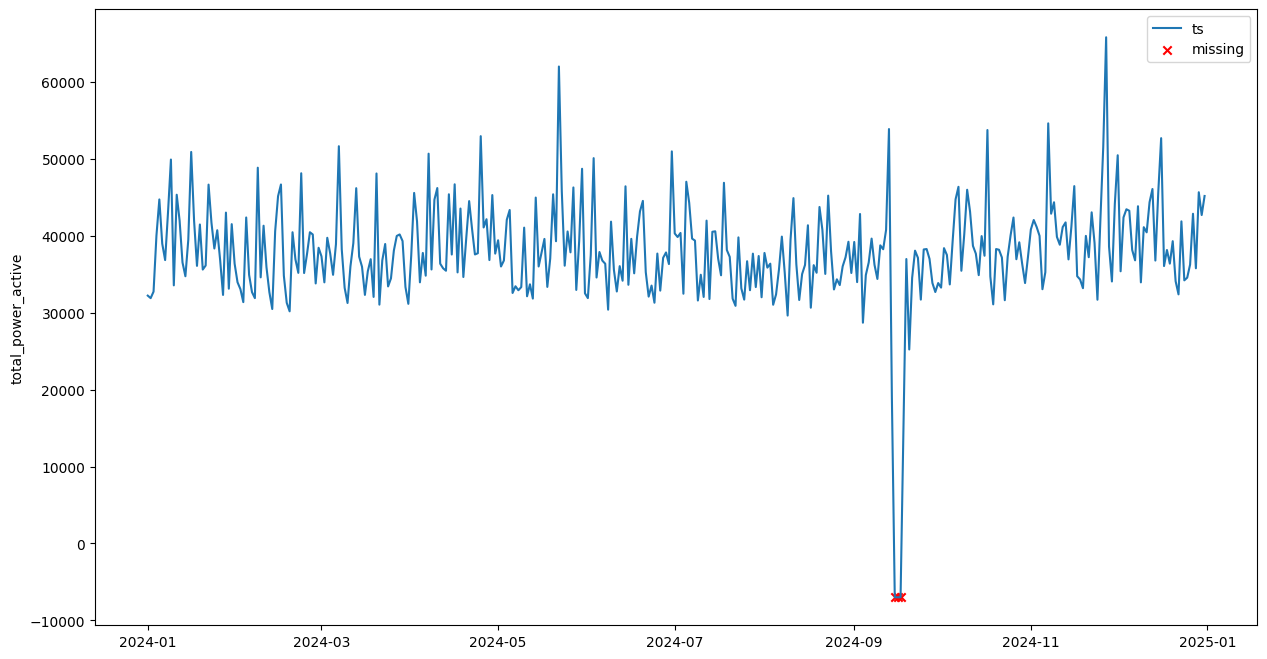

In [ ]:
plt.figure(figsize=(15,8))
daily_meter_data = meter_data_1.groupby(meter_data_1['time'].dt.floor('d'))

full_range = pd.DataFrame(
    index=pd.date_range(pd.DatetimeIndex(hourly_meter_data.indices.keys()).min(),\
                        pd.DatetimeIndex(hourly_meter_data.indices.keys()).max(), freq='d')
    )
print(full_range.index)

tot_pow_day_endog = full_range.join(daily_meter_data['total_power_active'].sum(), how='left').squeeze()

sns.lineplot(tot_pow_day_endog.fillna(-7000), label='ts')
plt.scatter(
    x=tot_pow_day_endog[tot_pow_day_endog.isna()].index,
    y=[-7000]*tot_pow_day_endog[tot_pow_day_endog.isna()].shape[0],
    color='red',
    marker='x',
    label='missing'
    )

plt.legend()

### Seasonality analysis

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

Frequency analysis

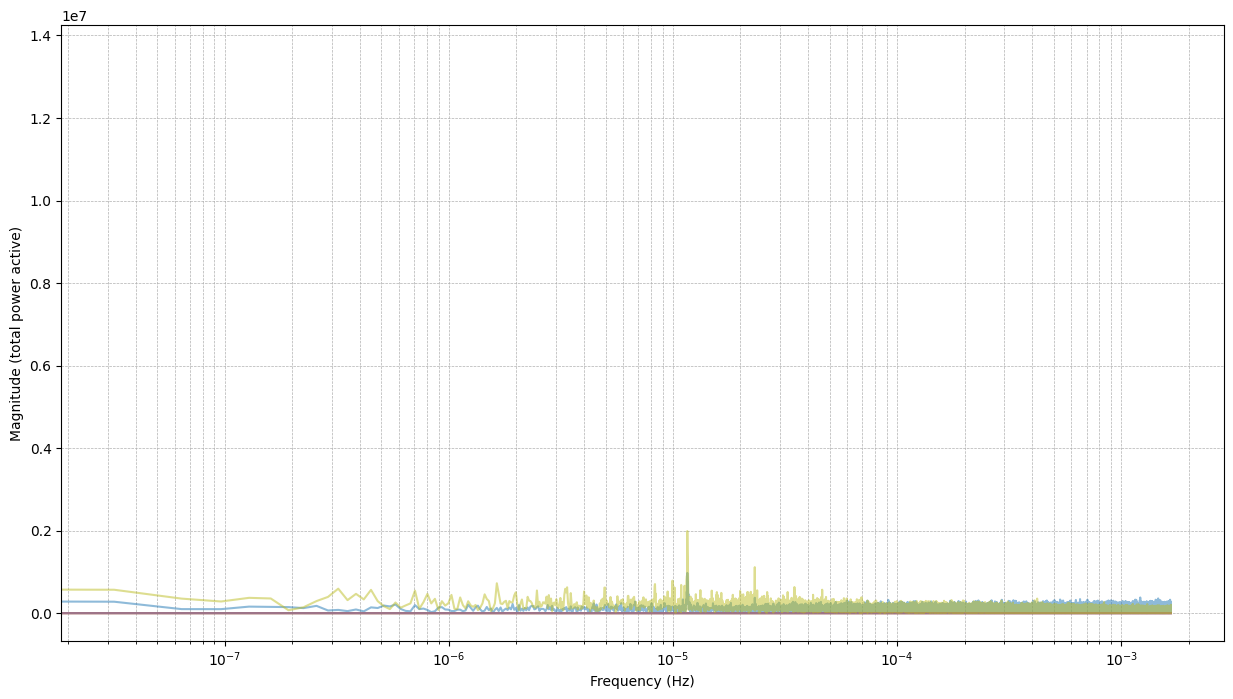

In [ ]:
period = 5 * 60 # 5 mins
fs = 1/period

plt.figure()

# check 10 sensors
start_sensor_index = 5
end_sensor_offset = 10
for id in smart_meter_data.device_id[start_sensor_index:start_sensor_index+end_sensor_offset]:
  meter_data_N = smart_meter_data[smart_meter_data.device_id == id]
  meter_data_N = meter_data_N.drop(columns=['device_id', 'serial_number'])
  signal = meter_data_N.groupby(meter_data_N['time']).mean()["total_power_active"]

  fft_result = np.fft.fft(signal)
  n = len(signal)
  freq = np.fft.fftfreq(n, d=1/fs)

  fft_result_shifted = np.fft.fftshift(fft_result)
  freq_shifted = np.fft.fftshift(freq)

  N = 10
  half_len = int(len(freq_shifted)/2)
  plt.plot(freq_shifted[half_len:],np.abs(fft_result_shifted[half_len:]), label=f"Device {id}", alpha=0.5)

plt.xscale("log")
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (total power active)")
plt.show()


#### Hourly

##### `total_energy_active`

In [ ]:
plot_acf(tot_eng_hour_endog.fillna(tot_eng_hour_endog.median()), lags=24*7, title='Autocorrelation (energy horly)');
plt.ylim(-0.1, 1.1)

In [ ]:
plot_pacf(tot_eng_hour_endog.fillna(tot_eng_hour_endog.median()), lags=24*7, title='Partial Autocorrelation (energy hourly)');
plt.ylim(-0.1, 1.1)

Biggest influence from **lag 1**

##### `total_power_active`

In [ ]:
plot_acf(tot_pow_hour_endog.fillna(tot_pow_hour_endog.median()), lags=24*7, title='Autocorrelation (power hourly)');
plt.scatter([1], [0.4], color='green', marker='x', label='1-hour lag')
plt.scatter([24], [0.4], color='green', marker='x', label='24-hour lag')
plt.scatter([48], [0.4], color='green', marker='x', label='48-hour lag')
plt.ylim(-0.1, 1.1)
plt.legend()

In [ ]:
plot_pacf(tot_pow_hour_endog.fillna(tot_pow_hour_endog.median()), lags=24*7, title='Partial Autocorrelation (power hourly)');
plt.scatter([1], [0.4], color='green', marker='x', label='1-hour lag')
plt.scatter([24], [0.4], color='green', marker='x', label='24-hour lag')
plt.scatter([48], [0.4], color='green', marker='x', label='48-hour lag')
plt.ylim(-0.1, 1.1)
plt.legend()

The biggest influence from **lags 1 (1 hour before), 24 and 48**

#### Daily

##### `total_energy_active`

In [ ]:
plot_acf(tot_eng_day_endog.fillna(tot_eng_day_endog.median()), lags=183, title='Autocorrelation (energy daily)');
plt.ylim(-0.5, 1.1)

In [ ]:
plot_pacf(tot_eng_day_endog.fillna(tot_eng_day_endog.median()), lags=183, title='Partial Autocorrelation (energy daily)');
plt.ylim(-0.3, 1.1)
plt.scatter([1], [0.98], color='green', marker='x', label='1-day lag')
plt.scatter([2], [0.5], color='green', marker='x', label='2-day lag')
plt.scatter([42], [0.4], color='green', marker='x', label='42-day lag')
plt.scatter([64], [0.4], color='red', marker='x', label='62-day negative lag')
plt.legend()

Biggest influence from **lags 1, 2, 42 and 62 days**

##### `total_power_active`

In [ ]:
plot_acf(tot_pow_day_endog.fillna(tot_pow_day_endog.median()), lags=183, title='Autocorrelation (power daily)');
plt.ylim(-0.5, 1.1)

In [ ]:
plot_pacf(tot_pow_day_endog.fillna(tot_pow_day_endog.median()), lags=183, title='Autocorrelation (power daily)');
plt.ylim(-0.5, 1.1)

Biggest influence from **lags 1 and 2 days**

#### Seasonal decomposition with (MSTL)

MSTL - Season-Trend decomposition using LOESS for multiple seasonalities

##### Hourly

###### `total_energy_active`

In [ ]:
from statsmodels.tsa.seasonal import MSTL

hourly_eng_decomposition = MSTL(
    tot_eng_hour_endog.fillna(tot_eng_hour_endog.median()),
    periods=[24, 24*7]
    ).fit()

In [ ]:
hourly_eng_decomposition.plot();

###### `total_power_active`

In [ ]:
hourly_pow_decomposition = MSTL(
    tot_pow_hour_endog.fillna(tot_pow_hour_endog.median()),
    periods=[24, 24*7]
    ).fit()

In [ ]:
hourly_pow_decomposition.plot();

##### Daily

###### `total_energy_active`

In [ ]:
daily_eng_decomposition = MSTL(
    tot_eng_day_endog.fillna(tot_eng_day_endog.median()),
    periods=[7]
    ).fit()

In [ ]:
daily_eng_decomposition.plot();

###### `total_power_active`

In [ ]:
daily_pow_decomposition = MSTL(
    tot_pow_day_endog.fillna(tot_pow_day_endog.median()),
    periods=[24, 24*7]
    ).fit()

In [ ]:
daily_pow_decomposition.plot();